# Labels and subjects

Compare label counts and variation across tasks. Set `COHORTS` to select years. Edit `DATA_DIR` below before running.

Requires Python 3.10+, NumPy, pandas, IPython, Matplotlib.

In [1]:
from pathlib import Path
from dataclasses import dataclass
from itertools import combinations_with_replacement
from typing import Iterable
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Data directory containing the 1year, 2year, and 3year folders.
DATA_DIR = Path(r"C:\Users\emanu\Documents\Progetti_python\SLD-slimGSGP\data")
COHORTS = None  # All years; use ["1year"] to select one cohort.

EDA_VALID_LABELS = (0, 1, 2)
EDA_UNKNOWN_LABEL = -1
EDA_RARE_CLASS_THRESHOLD = 5

In [2]:
@dataclass
class TaskTable:
    """One source file; source is relative to its cohort directory."""

    cohort: str
    source: str
    frame: pd.DataFrame

    @property
    def task(self) -> str:
        return str(Path(self.source).with_suffix(""))


def natural_key(value: str) -> tuple:
    """Sort numeric filename components numerically, with deterministic ties."""
    return tuple(
        (1, int(part)) if part.isdigit() else (0, part.casefold())
        for part in re.split(r"(\d+)", value)
    ) + ((0, value),)


def load_tasks(data_dir: Path, cohorts: Iterable[str] | None = None) -> list[TaskTable]:
    """Discover CSVs in natural order; preserve missing IDs and unknown labels."""
    root = Path(data_dir).expanduser()
    if not root.is_dir():
        raise FileNotFoundError(
            f"Set DATA_DIR to the data directory containing cohort folders: {root}"
        )
    selected = (
        list(cohorts)
        if cohorts is not None
        else [
            p.name for p in root.iterdir() if p.is_dir() and not p.name.startswith(".")
        ]
    )
    if len(selected) != len(set(selected)):
        raise ValueError("Select each cohort only once.")
    tables = []
    for cohort in sorted(selected, key=natural_key):
        directory = root / cohort
        if not directory.is_dir():
            raise FileNotFoundError(f"Cohort directory does not exist: {cohort}")
        files = sorted(
            (
                p
                for p in directory.rglob("*")
                if p.is_file() and p.suffix.lower() == ".csv"
            ),
            key=lambda p: natural_key(p.relative_to(directory).as_posix()),
        )
        if not files:
            raise FileNotFoundError(f"No task CSVs found in cohort: {cohort}")
        for path in files:
            frame = pd.read_csv(path, dtype="string")
            tables.append(
                TaskTable(cohort, path.relative_to(directory).as_posix(), frame)
            )
    if not tables:
        raise ValueError("No cohorts selected.")
    return tables


def cohort_tables(tables: list[TaskTable]) -> dict[str, list[TaskTable]]:
    result: dict[str, list[TaskTable]] = {}
    for table in tables:
        result.setdefault(table.cohort, []).append(table)
    return result


tables = load_tasks(DATA_DIR, cohorts=COHORTS)
pd.set_option("display.max_rows", 24)
pd.set_option("display.max_columns", 12)
print(
    "Loaded task files by cohort:",
    {c: len(g) for c, g in cohort_tables(tables).items()},
)

Loaded task files by cohort: {'1year': 21, '2year': 21, '3year': 18}


In [3]:
def valid_labels(series: pd.Series) -> pd.Series:
    numeric = pd.to_numeric(series, errors="coerce")
    return numeric.where(numeric.isin(EDA_VALID_LABELS))


def label_counts(tables: list[TaskTable]) -> pd.DataFrame:
    """Include absent valid classes, -1, unexpected tokens, and missing labels."""
    rows = []
    for table in tables:
        raw = table.frame["Label"]
        numeric = pd.to_numeric(raw, errors="coerce")
        eligible = int(valid_labels(raw).notna().sum())
        known = (*EDA_VALID_LABELS, EDA_UNKNOWN_LABEL)
        for label in known:
            count = int(numeric.eq(label).sum())
            rows.append(
                dict(
                    cohort=table.cohort,
                    task=table.task,
                    label=str(label),
                    label_kind="valid" if label in EDA_VALID_LABELS else "unresolved",
                    count=count,
                    raw_total=len(raw),
                    eligible_total=eligible,
                    raw_proportion=count / len(raw) if len(raw) else np.nan,
                    eligible_proportion=count / eligible
                    if eligible and label in EDA_VALID_LABELS
                    else np.nan,
                )
            )
        unexpected = raw[~numeric.isin(known)]
        for label, count in unexpected.value_counts(dropna=False).items():
            rows.append(
                dict(
                    cohort=table.cohort,
                    task=table.task,
                    label="<missing>" if pd.isna(label) else str(label),
                    label_kind="unexpected",
                    count=int(count),
                    raw_total=len(raw),
                    eligible_total=eligible,
                    raw_proportion=count / len(raw),
                    eligible_proportion=np.nan,
                )
            )
    return pd.DataFrame(rows)


def rare_class_flags(
    counts: pd.DataFrame, threshold: int = EDA_RARE_CLASS_THRESHOLD
) -> pd.DataFrame:
    valid = counts[counts.label_kind.eq("valid")].copy()
    grouped = valid.groupby(["cohort", "task"])
    valid["smallest_class_count"] = grouped["count"].transform("min")
    valid["majority_prevalence"] = grouped["eligible_proportion"].transform("max")
    valid["support"] = np.select(
        [valid["count"].eq(0), valid["count"].eq(1), valid["count"].lt(threshold)],
        ["absent", "singleton", "very_few"],
        default="at_least_threshold",
    )
    valid["warning_threshold"] = threshold
    return valid[
        [
            "cohort",
            "task",
            "label",
            "count",
            "support",
            "smallest_class_count",
            "majority_prevalence",
            "warning_threshold",
        ]
    ]


def subject_label_matrix(tables: list[TaskTable]) -> pd.DataFrame:
    """Return one cohort's outer join; refuse ambiguous or missing identifiers.

    Matching IDs and demographics only support identity linkage. Researcher
    confirmation of acquisition identifiers is still needed before final folds.
    """
    if not tables or len({t.cohort for t in tables}) != 1:
        raise ValueError("A subject label matrix requires exactly one cohort.")
    columns = {}
    for table in tables:
        ids = table.frame["Id"].astype("string")
        if ids.isna().any() or ids.str.strip().eq("").any() or ids.duplicated().any():
            raise ValueError(
                f"Missing or duplicate IDs prevent a safe join in {table.task}."
            )
        if table.task in columns:
            raise ValueError("Duplicate source task keys prevent a safe join.")
        columns[table.task] = pd.Series(
            table.frame.Label.to_numpy(), index=ids, name=table.task
        )
    matrix = pd.concat(columns, axis=1)
    matrix.index.name = "Id"
    return matrix.sort_index()


def subject_label_patterns(matrix: pd.DataFrame) -> pd.DataFrame:
    valid = matrix.apply(valid_labels)
    distinct = valid.nunique(axis=1)
    return pd.DataFrame(
        {
            "distinct_valid_labels": range(len(EDA_VALID_LABELS) + 1),
            "subjects": [
                int(distinct.eq(n).sum()) for n in range(len(EDA_VALID_LABELS) + 1)
            ],
        }
    )


def task_label_agreement(matrix: pd.DataFrame) -> pd.DataFrame:
    """Exact agreement; pairwise denominators exclude all unknown labels."""
    valid = matrix.apply(valid_labels)
    rows = []
    for left, right in combinations_with_replacement(valid.columns, 2):
        eligible = valid[left].notna() & valid[right].notna()
        n = int(eligible.sum())
        agree = int(valid.loc[eligible, left].eq(valid.loc[eligible, right]).sum())
        rows.append(
            dict(
                task_a=left,
                task_b=right,
                eligible_subjects=n,
                agreeing_subjects=agree,
                exact_agreement=agree / n if n else np.nan,
            )
        )
    return pd.DataFrame(rows)


counts = label_counts(tables)
rare = rare_class_flags(counts)
display(
    counts.groupby(["cohort", "label_kind", "label"], sort=False)["count"]
    .sum()
    .to_frame("raw_rows")
)
display(
    counts.loc[
        counts.label_kind.eq("valid"),
        [
            "cohort",
            "task",
            "label",
            "count",
            "raw_total",
            "eligible_total",
            "raw_proportion",
            "eligible_proportion",
        ],
    ].head(12)
)

raw_rows
cohort label_kind label          
1year  valid      0           783
                  1           923
                  2          1088
       unresolved -1          141
2year  valid      0           382
                  1           844
                  2          1153
       unresolved -1          666
3year  valid      0           114
                  1           467
                  2           619
       unresolved -1         1410

,cohort,task,label,count,raw_total,eligible_total,raw_proportion,eligible_proportion
0,1year,Task_1,0,0,140,0,0.000000,NaN
1,1year,Task_1,1,0,140,0,0.000000,NaN
2,1year,Task_1,2,0,140,0,0.000000,NaN
4,1year,Task_2,0,8,140,140,0.057143,0.057143
5,1year,Task_2,1,57,140,140,0.407143,0.407143
6,1year,Task_2,2,75,140,140,0.535714,0.535714
8,1year,Task_3,0,61,140,140,0.435714,0.435714
9,1year,Task_3,1,29,140,140,0.207143,0.207143
10,1year,Task_3,2,50,140,140,0.357143,0.357143
12,1year,Task_4,0,1,140,140,0.007143,0.007143


Stacked bars include every label; count heatmaps use `{0, 1, 2}`. Labels are nominal. `counts` gives proportions relative to raw and eligible rows. Agreement excludes unknown labels pairwise; the second agreement heatmap gives eligible counts.

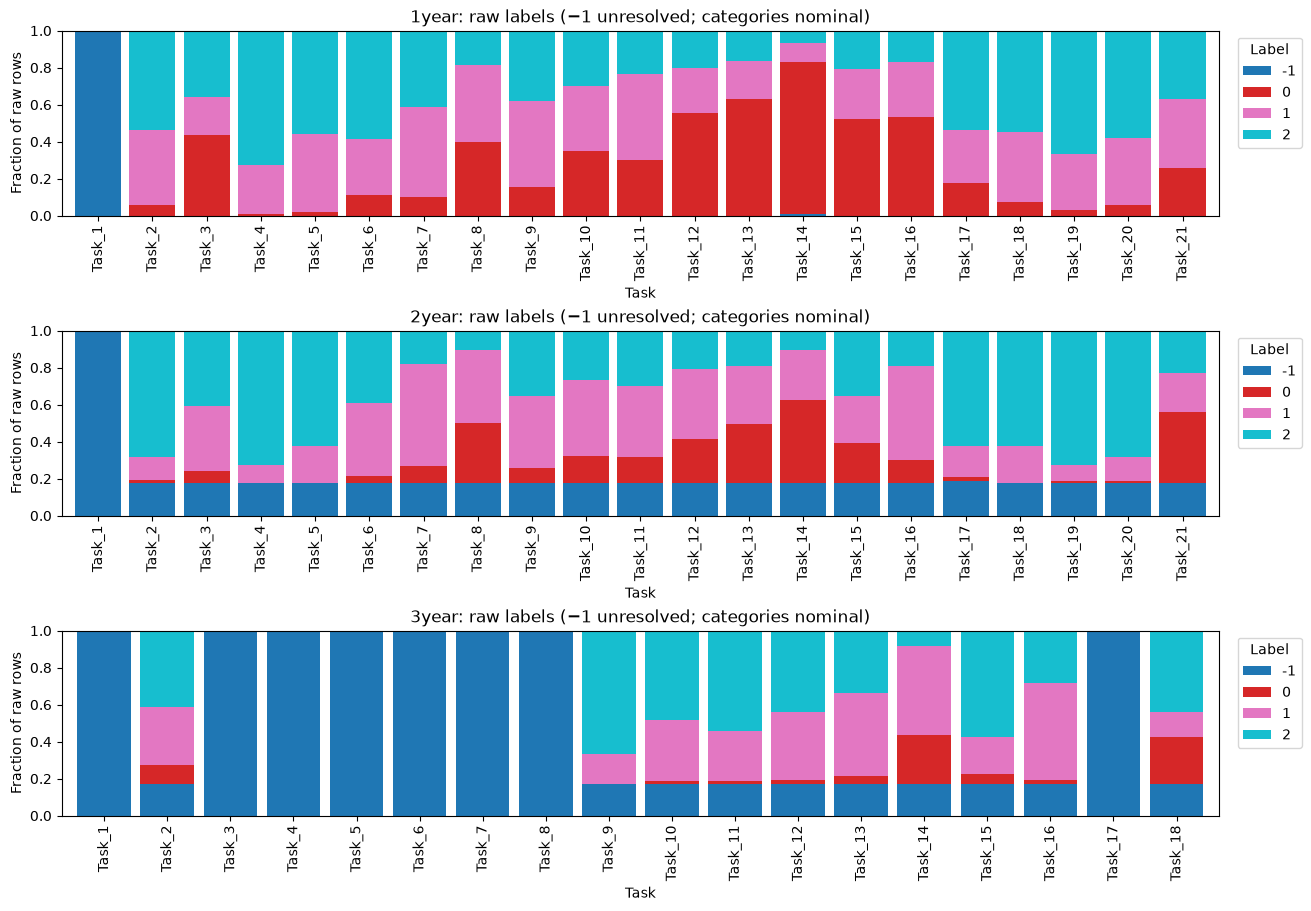

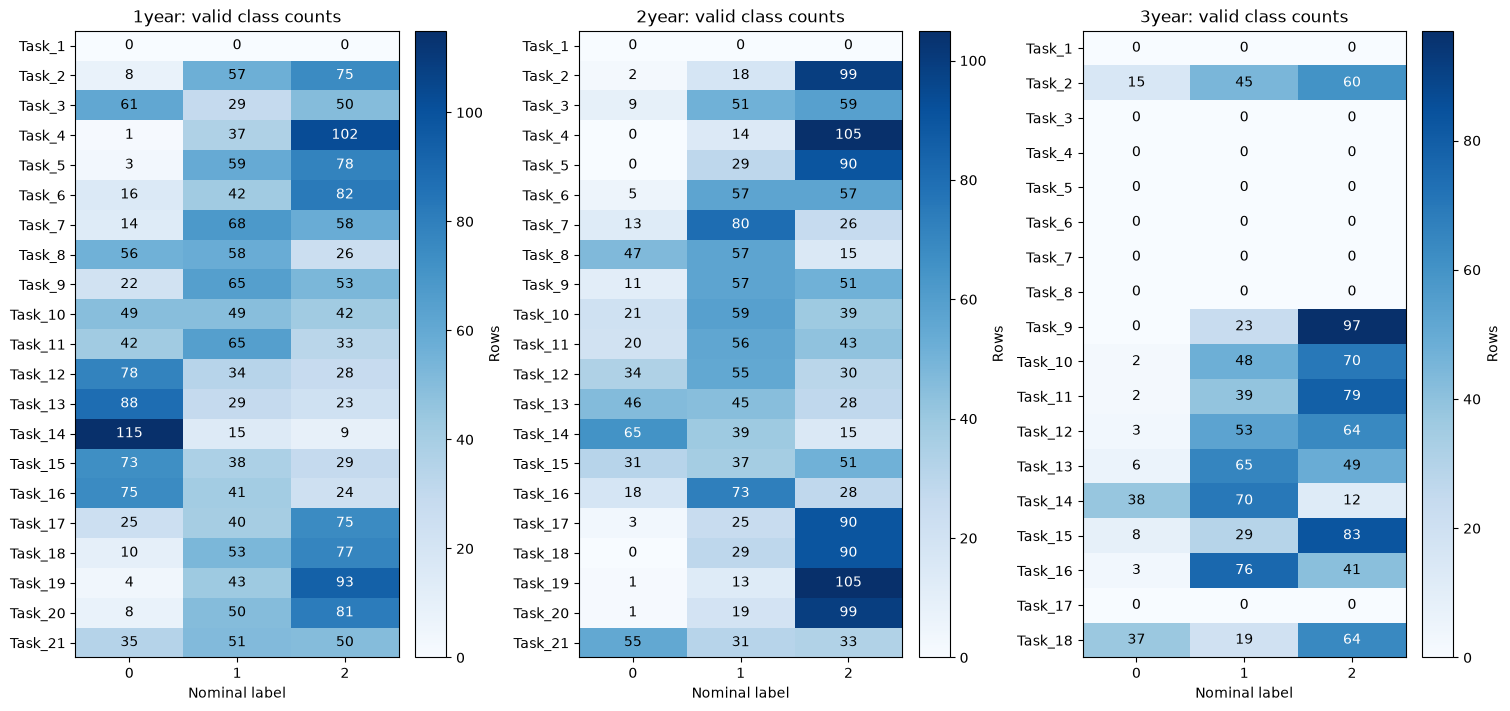

In [4]:
def plot_label_distributions(counts: pd.DataFrame) -> plt.Figure:
    cohorts = counts.cohort.unique()
    figure, axes = plt.subplots(
        len(cohorts),
        1,
        figsize=(13, 3 * len(cohorts)),
        squeeze=False,
        layout="constrained",
    )
    for ax, cohort in zip(axes.flat, cohorts):
        subset = counts[counts.cohort.eq(cohort)]
        proportions = subset.pivot(
            index="task", columns="label", values="raw_proportion"
        ).fillna(0)
        proportions = proportions.reindex(subset.task.drop_duplicates())
        proportions.plot.bar(stacked=True, ax=ax, width=0.85, colormap="tab10")
        ax.set(
            title=f"{cohort}: raw labels (−1 unresolved; categories nominal)",
            xlabel="Task",
            ylabel="Fraction of raw rows",
            ylim=(0, 1),
        )
        ax.legend(title="Label", bbox_to_anchor=(1.01, 1), loc="upper left")
    return figure


def plot_class_counts(counts: pd.DataFrame) -> plt.Figure:
    cohorts = counts.cohort.unique()
    figure, axes = plt.subplots(
        1,
        len(cohorts),
        figsize=(5 * len(cohorts), 7),
        squeeze=False,
        layout="constrained",
    )
    for ax, cohort in zip(axes.flat, cohorts):
        subset = counts[counts.cohort.eq(cohort) & counts.label_kind.eq("valid")]
        matrix = subset.pivot(index="task", columns="label", values="count")
        matrix = matrix.reindex(
            index=subset.task.drop_duplicates(),
            columns=[str(x) for x in EDA_VALID_LABELS],
        )
        heatmap = ax.imshow(matrix.to_numpy(), aspect="auto", cmap="Blues", vmin=0)
        ax.set(
            xticks=range(len(matrix.columns)),
            xticklabels=matrix.columns,
            yticks=range(len(matrix)),
            yticklabels=matrix.index,
            title=f"{cohort}: valid class counts",
            xlabel="Nominal label",
        )
        for row, column in np.ndindex(matrix.shape):
            ax.text(
                column,
                row,
                str(int(matrix.iloc[row, column])),
                ha="center",
                va="center",
                color="white"
                if matrix.iloc[row, column] > np.nanmax(matrix.to_numpy()) * 0.6
                else "black",
            )
        figure.colorbar(heatmap, ax=ax, label="Rows")
    return figure


plot_label_distributions(counts)
plt.show()
plot_class_counts(counts)
plt.show()

In [5]:
patterns, agreements, join_warnings = [], [], []
label_matrices = {}  # Private in-memory subject-level objects; never displayed or exported.
for cohort, group in cohort_tables(tables).items():
    try:
        matrix = subject_label_matrix(group)
    except (ValueError, KeyError) as error:
        join_warnings.append({"cohort": cohort, "reason": str(error)})
        continue
    label_matrices[cohort] = matrix
    patterns.append(subject_label_patterns(matrix).assign(cohort=cohort))
    agreements.append(task_label_agreement(matrix).assign(cohort=cohort))
if patterns:
    display(pd.concat(patterns, ignore_index=True))
if join_warnings:
    display(pd.DataFrame(join_warnings))

,distinct_valid_labels,subjects,cohort
0,0,0,1year
1,1,0,1year
2,2,6,1year
3,3,134,1year
4,0,26,2year
5,1,0,2year
6,2,13,2year
7,3,106,2year
8,0,25,3year
9,1,3,3year


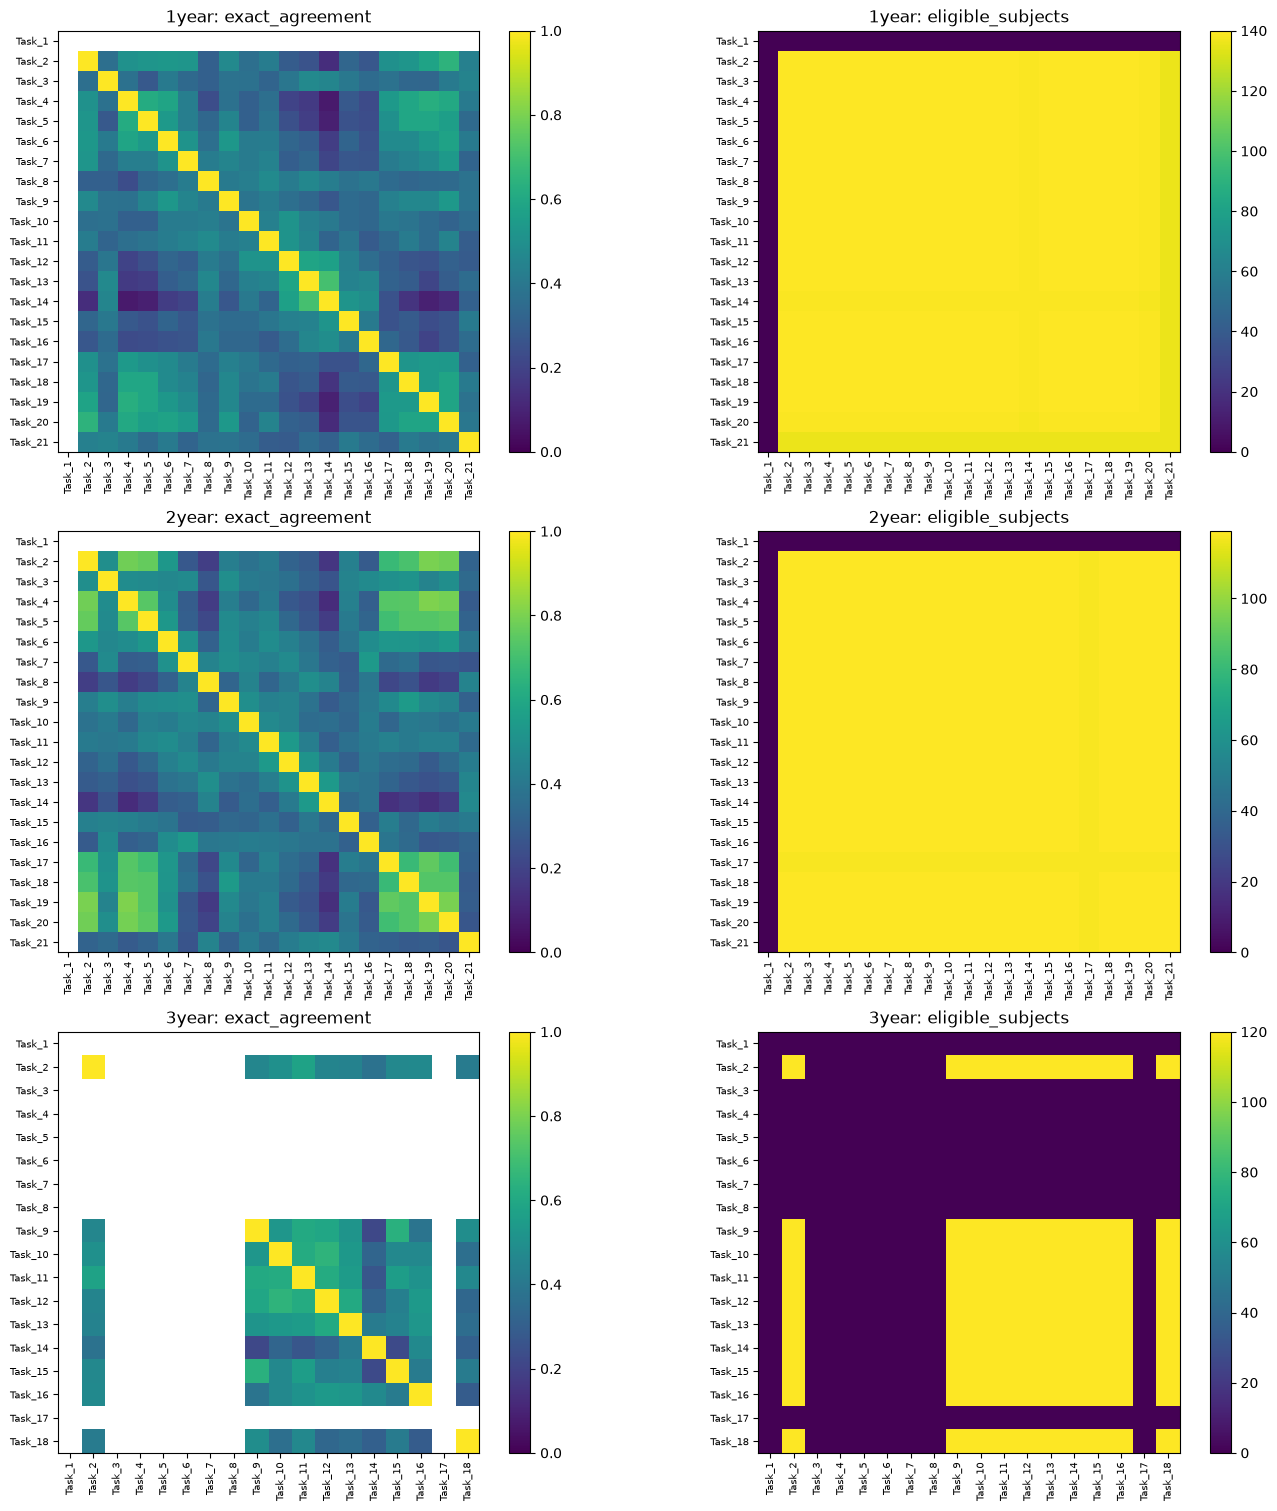

,min_pairwise_n,max_pairwise_n
cohort,,
1year,0,140
2year,0,119
3year,0,120


In [6]:
def plot_agreement(agreements: pd.DataFrame) -> plt.Figure:
    """Show exact agreement and a separate pairwise eligible-N heatmap."""
    cohorts = agreements.cohort.unique()
    figure, axes = plt.subplots(
        len(cohorts),
        2,
        figsize=(14, 5 * len(cohorts)),
        squeeze=False,
        layout="constrained",
    )
    for row, cohort in enumerate(cohorts):
        subset = agreements[agreements.cohort.eq(cohort)]
        tasks = list(dict.fromkeys([*subset.task_a, *subset.task_b]))
        for column, metric in enumerate(("exact_agreement", "eligible_subjects")):
            matrix = pd.DataFrame(np.nan, index=tasks, columns=tasks)
            for record in subset.itertuples():
                matrix.loc[record.task_a, record.task_b] = getattr(record, metric)
                matrix.loc[record.task_b, record.task_a] = getattr(record, metric)
            ax = axes[row, column]
            kwargs = (
                dict(vmin=0, vmax=1) if metric == "exact_agreement" else dict(vmin=0)
            )
            heatmap = ax.imshow(matrix, cmap="viridis", **kwargs)
            ax.set(
                title=f"{cohort}: {metric}",
                xticks=range(len(tasks)),
                yticks=range(len(tasks)),
                xticklabels=tasks,
                yticklabels=tasks,
            )
            ax.tick_params(axis="x", labelrotation=90, labelsize=7)
            ax.tick_params(axis="y", labelsize=7)
            figure.colorbar(heatmap, ax=ax)
    return figure


if agreements:
    agreement = pd.concat(agreements, ignore_index=True)
    plot_agreement(agreement)
    plt.show()
    display(
        agreement.groupby("cohort").agg(
            min_pairwise_n=("eligible_subjects", "min"),
            max_pairwise_n=("eligible_subjects", "max"),
        )
    )

In [7]:
display(rare.loc[rare.support.ne("at_least_threshold")])
task_imbalance = rare.groupby(["cohort", "task"], sort=False).agg(
    smallest_class_count=("smallest_class_count", "first"),
    majority_prevalence=("majority_prevalence", "first"),
)
display(
    task_imbalance.groupby("cohort").agg(
        worst_minority_count=("smallest_class_count", "min"),
        largest_majority_prevalence=("majority_prevalence", "max"),
    )
)

,cohort,task,label,count,support,smallest_class_count,majority_prevalence,warning_threshold
0,1year,Task_1,0,0,absent,0,NaN,5
1,1year,Task_1,1,0,absent,0,NaN,5
2,1year,Task_1,2,0,absent,0,NaN,5
12,1year,Task_4,0,1,singleton,1,0.728571,5
16,1year,Task_5,0,3,very_few,3,0.557143,5
...,...,...,...,...,...,...,...,...
212,3year,Task_12,0,3,very_few,3,0.533333,5
228,3year,Task_16,0,3,very_few,3,0.633333,5
232,3year,Task_17,0,0,absent,0,NaN,5
233,3year,Task_17,1,0,absent,0,NaN,5


,worst_minority_count,largest_majority_prevalence
cohort,,
1year,0,0.827338
2year,0,0.882353
3year,0,0.808333
